In [ ]:
import re
import time
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     cross_val_score, GridSearchCV)
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             precision_recall_fscore_support, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report)

warnings.filterwarnings('ignore')
plt.rcParams.update({'figure.dpi': 100, 'axes.spines.top': False, 'axes.spines.right': False})

for pkg in ['punkt', 'punkt_tab', 'stopwords']:
    nltk.download(pkg, quiet=True)

In [ ]:
DATA_PATH = 'twitter_training.csv'
COLS = ['ID', 'Brand', 'Sentiment', 'Text']

if DATA_PATH.lower().endswith(('.xlsx', '.xls')):
    df = pd.read_excel(DATA_PATH, header=None, names=COLS)
else:
    df = pd.read_csv(DATA_PATH, header=None, names=COLS)

print('Raw shape:', df.shape)
df.head()

Raw shape: (74682, 4)


,ID,Brand,Sentiment,Text
0,2401,Borderlands,Positive,im getting on borderlands and i will murder yo...
1,2401,Borderlands,Positive,I am coming to the borders and I will kill you...
2,2401,Borderlands,Positive,im getting on borderlands and i will kill you ...
3,2401,Borderlands,Positive,im coming on borderlands and i will murder you...
4,2401,Borderlands,Positive,im getting on borderlands 2 and i will murder ...


In [ ]:
LABELS = ['Positive', 'Negative', 'Neutral', 'Irrelevant']
df['Sentiment'] = df['Sentiment'].astype(str).str.split('\n').str[0].str.strip()
df = df.dropna(subset=['Text', 'Sentiment'])
df = df[df['Sentiment'].isin(LABELS)]
df = df.drop_duplicates(subset=['Text', 'Sentiment']).reset_index(drop=True)

print('Clean shape:', df.shape)
print(df['Sentiment'].value_counts())

Clean shape: (69769, 4)
Sentiment
Negative      21237
Positive      19138
Neutral       17110
Irrelevant    12284
Name: count, dtype: int64


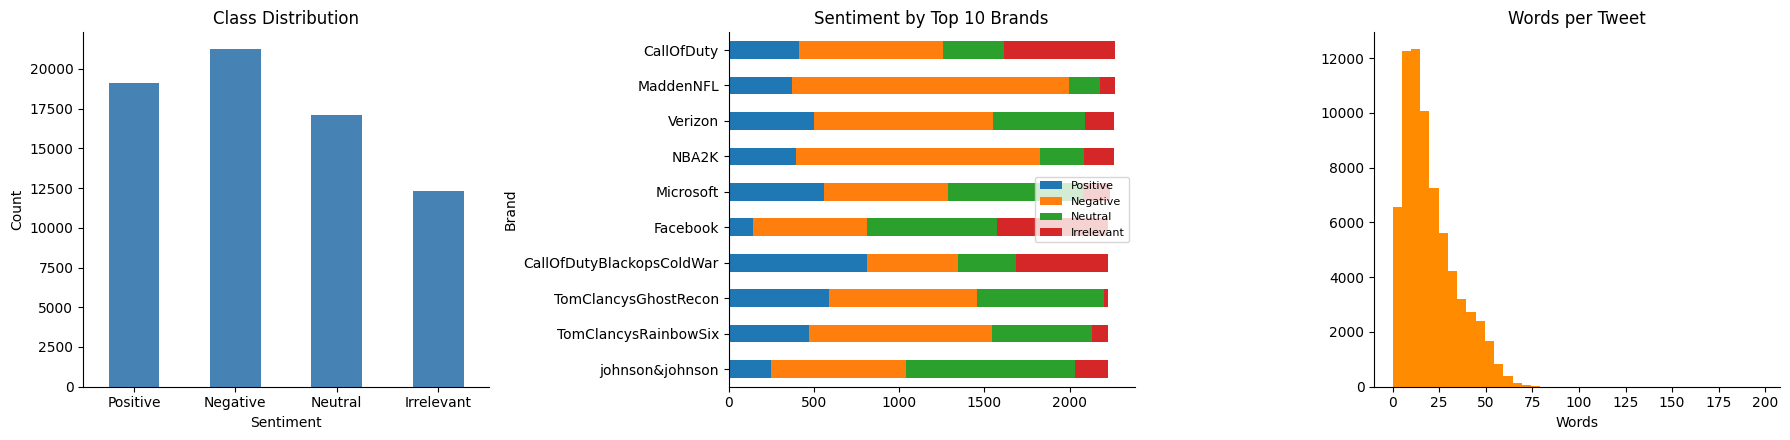

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

df['Sentiment'].value_counts().reindex(LABELS).plot(kind='bar', color='steelblue', ax=axes[0],
                                                    title='Class Distribution', rot=0)
axes[0].set_ylabel('Count')
top_brands = df['Brand'].value_counts().head(10).index
ct = pd.crosstab(df['Brand'], df['Sentiment']).loc[top_brands, LABELS]
ct.plot(kind='barh', stacked=True, ax=axes[1], title='Sentiment by Top 10 Brands')
axes[1].invert_yaxis()
axes[1].legend(fontsize=8)
df['n_words'] = df['Text'].astype(str).str.split().str.len()
axes[2].hist(df['n_words'], bins=40, color='darkorange')
axes[2].set_title('Words per Tweet')
axes[2].set_xlabel('Words')

plt.tight_layout()
plt.show()

In [ ]:
NEGATIONS = {'no', 'not', 'nor', 'never', 'neither', 'without'}
stop_words = set(stopwords.words('english')) - NEGATIONS

def preprocess(text):
    text = str(text).lower()
    text = text.replace('<unk>', ' ')
    text = re.sub(r'http\S+|www\.\S+|pic\.twitter\S+', ' ', text)
    text = re.sub(r'@\w+', ' ', text)
    text = re.sub(r'[^a-z\s]', ' ', text)
    tokens = word_tokenize(text)
    tokens = [t for t in tokens if t not in stop_words and len(t) > 1]
    return ' '.join(tokens)

df['Clean_Text'] = df['Text'].apply(preprocess)
df = df[df['Clean_Text'].str.strip() != ''].reset_index(drop=True)
print('Rows after preprocessing:', len(df))
df[['Text', 'Clean_Text', 'Sentiment']].head(8)

Rows after preprocessing: 69090


,Text,Clean_Text,Sentiment
0,im getting on borderlands and i will murder yo...,im getting borderlands murder,Positive
1,I am coming to the borders and I will kill you...,coming borders kill,Positive
2,im getting on borderlands and i will kill you ...,im getting borderlands kill,Positive
3,im coming on borderlands and i will murder you...,im coming borderlands murder,Positive
4,im getting on borderlands 2 and i will murder ...,im getting borderlands murder,Positive
5,im getting into borderlands and i can murder y...,im getting borderlands murder,Positive
6,So I spent a few hours making something for fu...,spent hours making something fun know huge fan...,Positive
7,So I spent a couple of hours doing something f...,spent couple hours something fun know huge bor...,Positive


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    df['Clean_Text'], df['Sentiment'],
    test_size=0.2, random_state=42, stratify=df['Sentiment'])

print('Train:', len(X_train), ' Test:', len(X_test))
print(y_test.value_counts(normalize=True).round(3))

Train: 55272  Test: 13818
Sentiment
Negative      0.305
Positive      0.274
Neutral       0.245
Irrelevant    0.176
Name: proportion, dtype: float64


In [ ]:
tfidf = TfidfVectorizer(ngram_range=(1, 2), max_features=100000, min_df=2, sublinear_tf=True)
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)
print('TF-IDF matrix (train):', X_train_tfidf.shape)

TF-IDF matrix (train): (55272, 100000)


In [ ]:
models = {
    'Multinomial NB': MultinomialNB(alpha=0.3),
    'Logistic Regression': LogisticRegression(max_iter=1000, C=5, random_state=42),
    'Linear SVM': LinearSVC(C=1.0, random_state=42),
}

predictions, rows = {}, []

def score_row(name, y_true, y_pred, fit_seconds):
    return {
        'Model': name,
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, average='weighted', zero_division=0),
        'Recall': recall_score(y_true, y_pred, average='weighted', zero_division=0),
        'F1-Score': f1_score(y_true, y_pred, average='weighted', zero_division=0),
        'Macro F1': f1_score(y_true, y_pred, average='macro', zero_division=0),
        'Fit time (s)': fit_seconds,
    }

for name, model in models.items():
    t0 = time.time()
    model.fit(X_train_tfidf, y_train)
    fit_s = time.time() - t0
    y_pred = model.predict(X_test_tfidf)
    predictions[name] = y_pred
    rows.append(score_row(name, y_test, y_pred, fit_s))
    print(f' {name} ')
    print(classification_report(y_test, y_pred, labels=LABELS, zero_division=0))

results_df = pd.DataFrame(rows).set_index('Model')
results_df.round(4)

 Multinomial NB 
              precision    recall  f1-score   support

    Positive       0.88      0.93      0.90      3790
    Negative       0.88      0.95      0.91      4210
     Neutral       0.94      0.88      0.90      3385
  Irrelevant       0.97      0.84      0.90      2433

    accuracy                           0.91     13818
   macro avg       0.92      0.90      0.90     13818
weighted avg       0.91      0.91      0.91     13818

 Logistic Regression 
              precision    recall  f1-score   support

    Positive       0.91      0.93      0.92      3790
    Negative       0.92      0.95      0.93      4210
     Neutral       0.93      0.91      0.92      3385
  Irrelevant       0.94      0.89      0.91      2433

    accuracy                           0.92     13818
   macro avg       0.92      0.92      0.92     13818
weighted avg       0.92      0.92      0.92     13818

 Linear SVM 
              precision    recall  f1-score   support

    Positive       0.93

,Accuracy,Precision,Recall,F1-Score,Macro F1,Fit time (s)
Model,,,,,,
Multinomial NB,0.9058,0.9088,0.9058,0.9056,0.9046,0.1476
Logistic Regression,0.9223,0.9226,0.9223,0.9223,0.9209,43.5863
Linear SVM,0.9388,0.9390,0.9388,0.9387,0.9378,3.3168


In [ ]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = {}

for name, clf in models.items():
    pipe = Pipeline([
        ('tfidf', TfidfVectorizer(ngram_range=(1, 2), max_features=100000, min_df=2, sublinear_tf=True)),
        ('clf', clone(clf)),
    ])
    cv_scores[name] = cross_val_score(pipe, X_train, y_train, cv=skf, scoring='accuracy', n_jobs=-1)
    print(f'{name:22s} CV accuracy: {cv_scores[name].mean():.4f} +/- {cv_scores[name].std():.4f}')

Multinomial NB         CV accuracy: 0.8858 +/- 0.0032
Logistic Regression    CV accuracy: 0.9065 +/- 0.0021
Linear SVM             CV accuracy: 0.9240 +/- 0.0025


In [ ]:
svm_pipe = Pipeline([
    ('tfidf', TfidfVectorizer(max_features=100000, min_df=2, sublinear_tf=True)),
    ('clf', LinearSVC(random_state=42)),
])
param_grid = {
    'tfidf__ngram_range': [(1, 1), (1, 2), (1, 3)],
    'clf__C': [0.3, 1, 3],
}
grid = GridSearchCV(svm_pipe, param_grid, cv=3, scoring='f1_weighted', n_jobs=-1)
t0 = time.time()
grid.fit(X_train, y_train)
tuned_fit_s = time.time() - t0

print('Best params :', grid.best_params_)
print('Best CV F1  :', round(grid.best_score_, 4))

tuned_pred = grid.best_estimator_.predict(X_test)
predictions['Linear SVM (tuned)'] = tuned_pred

results_df = pd.concat([results_df,
                        pd.DataFrame([score_row('Linear SVM (tuned)', y_test, tuned_pred, tuned_fit_s)])
                        .set_index('Model')])
results_df.round(4)

Best params : {'clf__C': 3, 'tfidf__ngram_range': (1, 2)}
Best CV F1  : 0.9069


,Accuracy,Precision,Recall,F1-Score,Macro F1,Fit time (s)
Model,,,,,,
Multinomial NB,0.9058,0.9088,0.9058,0.9056,0.9046,0.1476
Logistic Regression,0.9223,0.9226,0.9223,0.9223,0.9209,43.5863
Linear SVM,0.9388,0.9390,0.9388,0.9387,0.9378,3.3168
Linear SVM (tuned),0.9380,0.9381,0.9380,0.9380,0.9370,122.5394


## 8. Graphs

### 8.1 Accuracy comparison

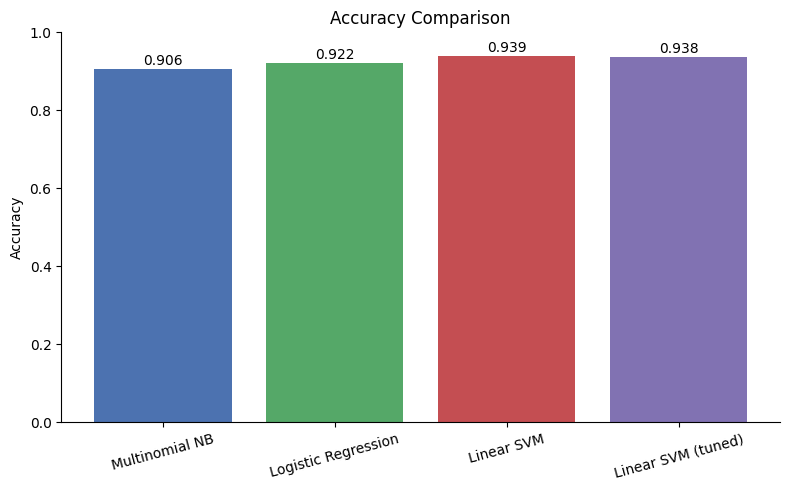

In [ ]:
colors = ['#4C72B0', '#55A868', '#C44E52', '#8172B2']
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(results_df.index, results_df['Accuracy'], color=colors[:len(results_df)])
ax.set_ylim(0, 1)
ax.set_ylabel('Accuracy')
ax.set_title('Accuracy Comparison')
for b in bars:
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.01,
            f'{b.get_height():.3f}', ha='center')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

### 8.2 Metrics bar chart (Accuracy, Precision, Recall, F1)

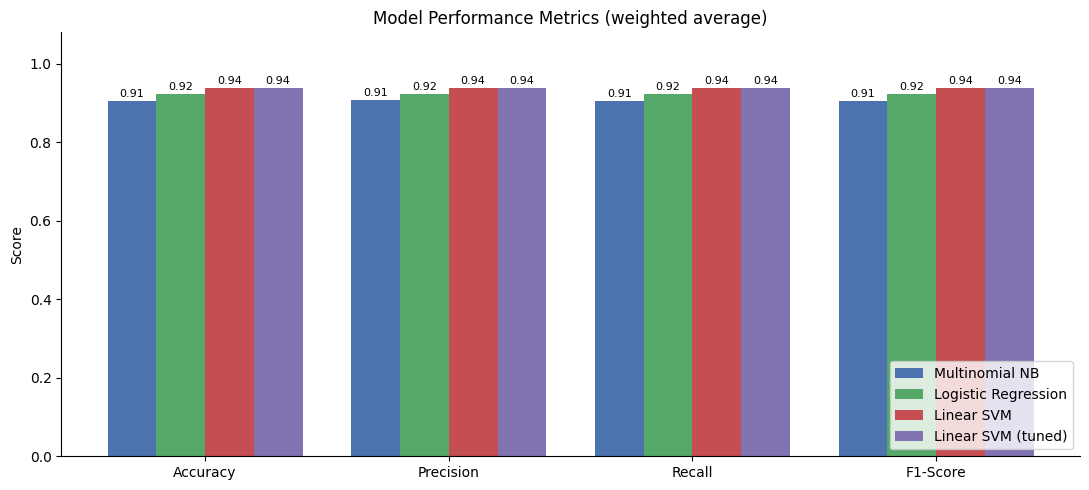

In [ ]:
metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
x = np.arange(len(metrics))
n = len(results_df)
width = 0.8 / n

fig, ax = plt.subplots(figsize=(11, 5))
for i, (name, row) in enumerate(results_df.iterrows()):
    vals = [row[m] for m in metrics]
    rects = ax.bar(x + (i - (n - 1) / 2) * width, vals, width, label=name, color=colors[i])
    for r in rects:
        ax.text(r.get_x() + r.get_width() / 2, r.get_height() + 0.01,
                f'{r.get_height():.2f}', ha='center', fontsize=8)

ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.set_ylim(0, 1.08)
ax.set_ylabel('Score')
ax.set_title('Model Performance Metrics (weighted average)')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

### 8.3 Cross-validation accuracy

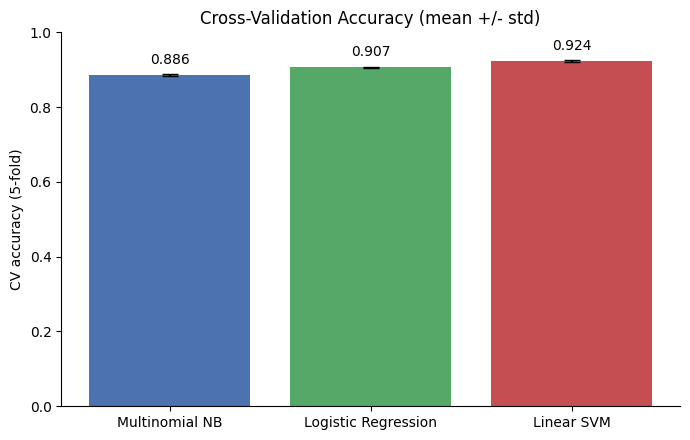

In [ ]:
names = list(cv_scores)
means = [cv_scores[k].mean() for k in names]
stds = [cv_scores[k].std() for k in names]

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.bar(names, means, yerr=stds, capsize=6, color=colors[:len(names)])
ax.set_ylim(0, 1)
ax.set_ylabel('CV accuracy (5-fold)')
ax.set_title('Cross-Validation Accuracy (mean +/- std)')
for i, m in enumerate(means):
    ax.text(i, m + 0.03, f'{m:.3f}', ha='center')
plt.tight_layout()
plt.show()

### 8.4 Confusion matrices (all models)

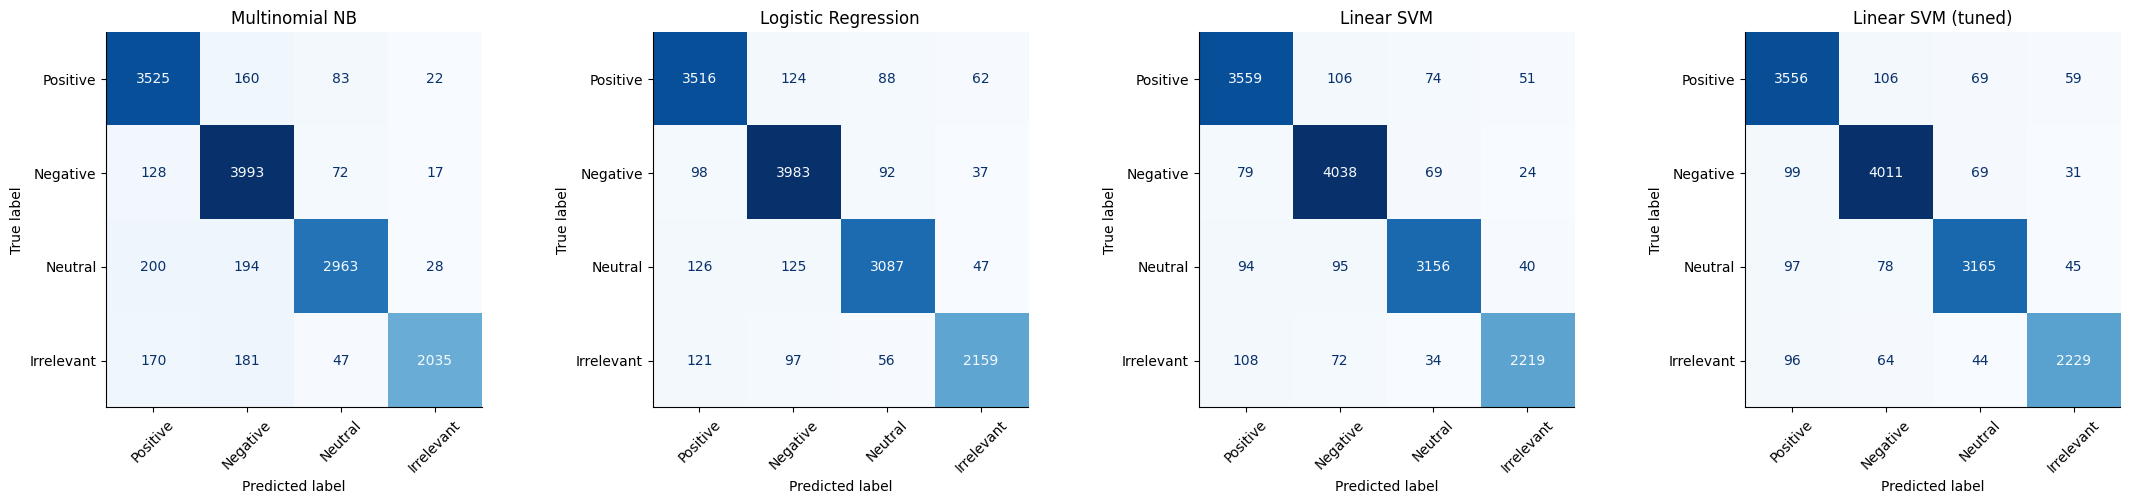

In [ ]:
fig, axes = plt.subplots(1, len(predictions), figsize=(5.5 * len(predictions), 5))
for ax, (name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, y_pred, labels=LABELS)
    ConfusionMatrixDisplay(cm, display_labels=LABELS).plot(ax=ax, cmap='Blues', colorbar=False,
                                                           xticks_rotation=45)
    ax.set_title(name)
plt.tight_layout()
plt.show()

### 8.5 Best model: per-class metrics and normalized confusion matrix

Best model by accuracy: Linear SVM


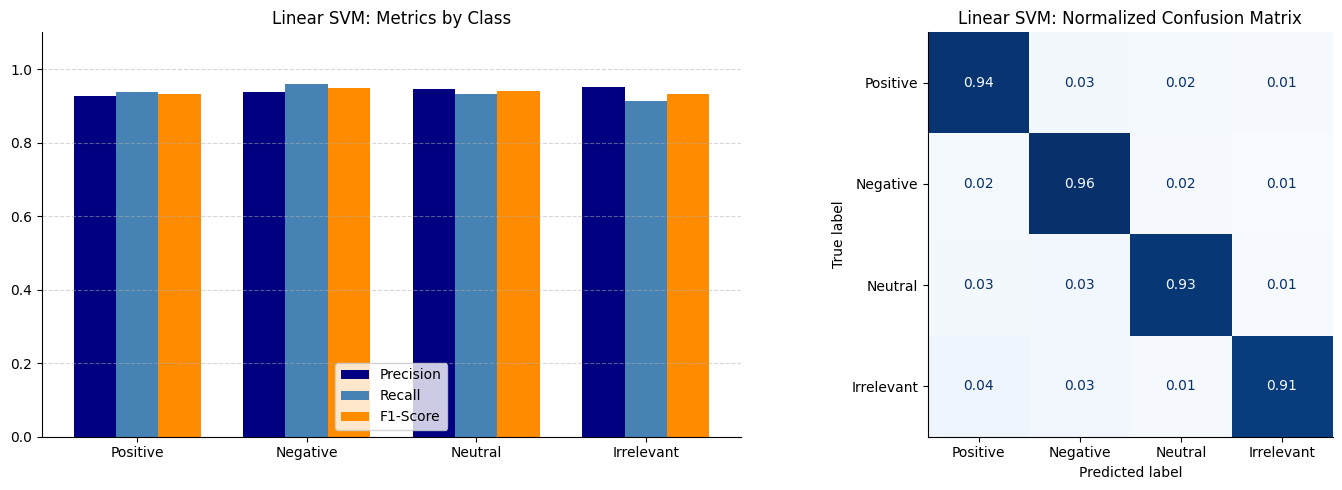

,Precision,Recall,F1,Support
Positive,0.9268,0.9391,0.9329,3790
Negative,0.9367,0.9591,0.9478,4210
Neutral,0.9469,0.9323,0.9396,3385
Irrelevant,0.9507,0.9120,0.9310,2433


In [ ]:
best_name = results_df['Accuracy'].idxmax()
best_pred = predictions[best_name]
print('Best model by accuracy:', best_name)

prec, rec, f1, support = precision_recall_fscore_support(y_test, best_pred, labels=LABELS, zero_division=0)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

xi = np.arange(len(LABELS))
w = 0.25
axes[0].bar(xi - w, prec, w, label='Precision', color='navy')
axes[0].bar(xi, rec, w, label='Recall', color='steelblue')
axes[0].bar(xi + w, f1, w, label='F1-Score', color='darkorange')
axes[0].set_xticks(xi)
axes[0].set_xticklabels(LABELS)
axes[0].set_ylim(0, 1.1)
axes[0].set_title(f'{best_name}: Metrics by Class')
axes[0].legend()
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

ConfusionMatrixDisplay.from_predictions(y_test, best_pred, labels=LABELS, normalize='true',
                                        cmap='Blues', ax=axes[1], colorbar=False,
                                        values_format='.2f')
axes[1].set_title(f'{best_name}: Normalized Confusion Matrix')

plt.tight_layout()
plt.show()

pd.DataFrame({'Precision': prec, 'Recall': rec, 'F1': f1, 'Support': support}, index=LABELS).round(4)

## 9. Interpretation
### 9.1 Top TF-IDF features per class (Logistic Regression coefficients)

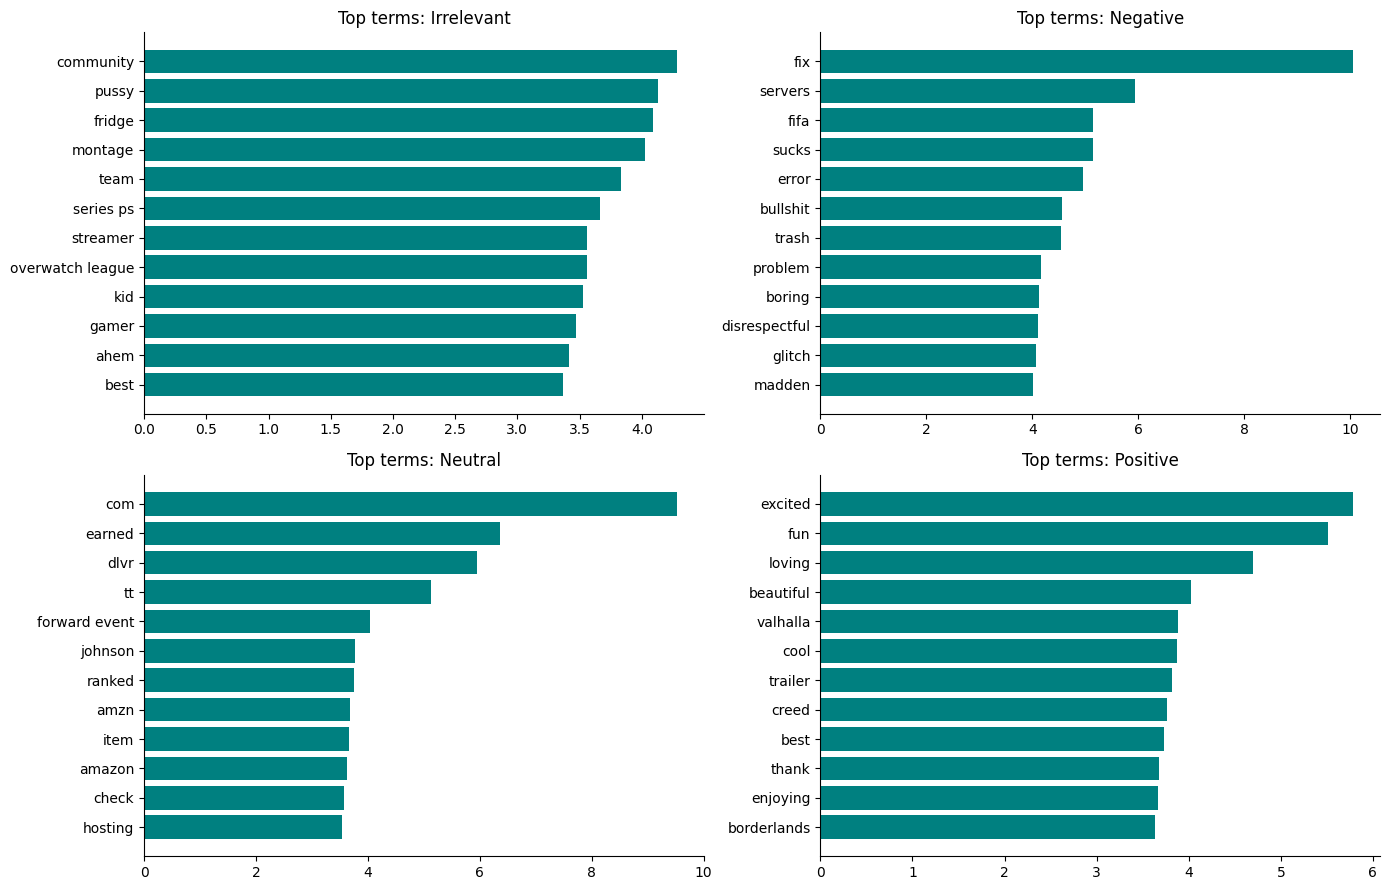

In [ ]:
lr = models['Logistic Regression']
feature_names = np.array(tfidf.get_feature_names_out())

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, cls_idx in zip(axes.ravel(), range(len(lr.classes_))):
    coefs = lr.coef_[cls_idx]
    top = np.argsort(coefs)[-12:]
    ax.barh(feature_names[top], coefs[top], color='teal')
    ax.set_title(f'Top terms: {lr.classes_[cls_idx]}')
plt.tight_layout()
plt.show()

### 9.2 Error analysis

In [ ]:
eval_df = pd.DataFrame({
    'Brand': df.loc[X_test.index, 'Brand'],
    'Text': df.loc[X_test.index, 'Text'],
    'Actual': y_test,
    'Predicted': best_pred,
})
errors = eval_df[eval_df['Actual'] != eval_df['Predicted']]
print(f'Misclassified: {len(errors)} of {len(eval_df)} ({len(errors) / len(eval_df):.1%})\n')

print('Most common confusions (Actual -> Predicted):')
print(errors.groupby(['Actual', 'Predicted']).size().sort_values(ascending=False).head(8))

errors.sample(10, random_state=1)[['Actual', 'Predicted', 'Text']]

Misclassified: 846 of 13818 (6.1%)

Most common confusions (Actual -> Predicted):
Actual      Predicted
Irrelevant  Positive     108
Positive    Negative     106
Neutral     Negative      95
            Positive      94
Negative    Positive      79
Positive    Neutral       74
Irrelevant  Negative      72
Negative    Neutral       69
dtype: int64


,Actual,Predicted,Text
19593,Negative,Neutral,Das Dammmmmmmn!!!!.
30728,Positive,Negative,Why am I the only one who still enjoys 14 days?
59485,Negative,Neutral,And THIS... IS ON MAJOR!!!!!!!!!
27219,Neutral,Irrelevant,us
36373,Positive,Irrelevant,I love my core stone that flows to people
48125,Positive,Neutral,"Leave me alone, I'm in a big red death mood pi..."
8347,Neutral,Irrelevant,Our Los
3747,Irrelevant,Positive,Epic hallucinations
36778,Negative,Positive,It was pretty easy to get them.
60677,Irrelevant,Negative,use @ tcbandages instead. they were with the s...


### 9.3 Brand-level view (test set, predicted vs actual)

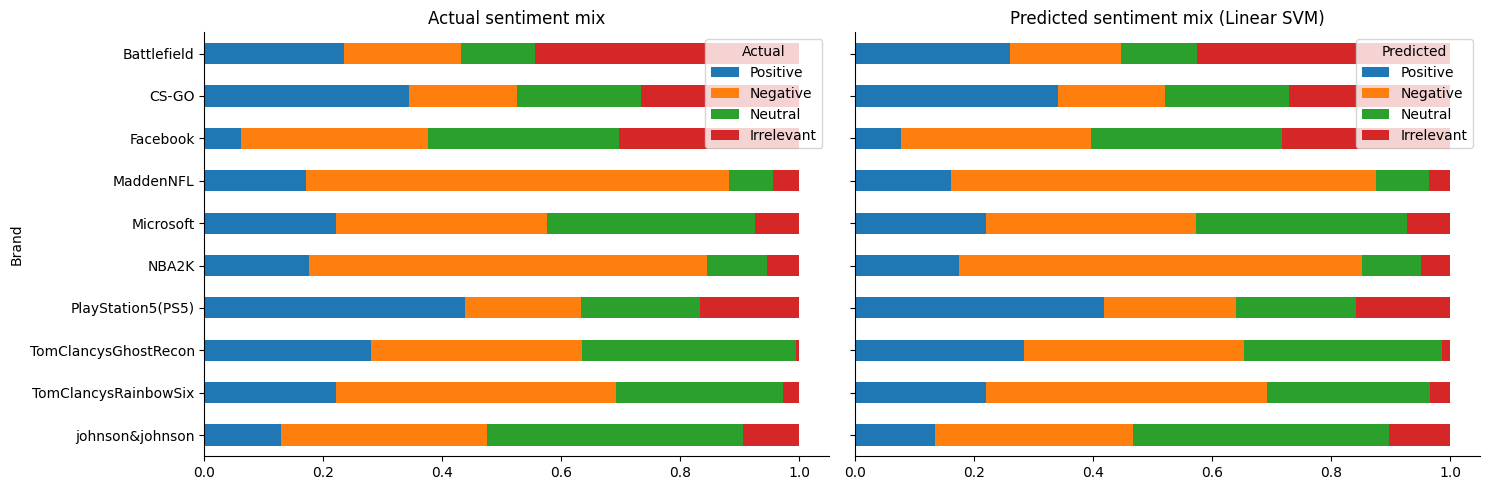

In [ ]:
top_b = eval_df['Brand'].value_counts().head(10).index
sub = eval_df[eval_df['Brand'].isin(top_b)]

actual_mix = pd.crosstab(sub['Brand'], sub['Actual'], normalize='index').reindex(columns=LABELS)
pred_mix = pd.crosstab(sub['Brand'], sub['Predicted'], normalize='index').reindex(columns=LABELS)

fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
actual_mix.plot(kind='barh', stacked=True, ax=axes[0], title='Actual sentiment mix')
pred_mix.plot(kind='barh', stacked=True, ax=axes[1], title=f'Predicted sentiment mix ({best_name})')
axes[0].invert_yaxis()
plt.tight_layout()
plt.show()

## 10. Save the pipeline and build an inference function
A Logistic Regression pipeline is used for serving because it returns class probabilities (Linear SVM does not).

In [ ]:
best_ngram = grid.best_params_['tfidf__ngram_range']

service_pipe = Pipeline([
    ('tfidf', TfidfVectorizer(ngram_range=best_ngram, max_features=100000, min_df=2, sublinear_tf=True)),
    ('clf', LogisticRegression(max_iter=1000, C=5, random_state=42)),
])
service_pipe.fit(X_train, y_train)
print('Serving pipeline test accuracy:', round(accuracy_score(y_test, service_pipe.predict(X_test)), 4))

joblib.dump(service_pipe, 'sentiment_pipeline.joblib')
joblib.dump(grid.best_estimator_, 'sentiment_linear_svm_tuned.joblib')
print('Saved: sentiment_pipeline.joblib, sentiment_linear_svm_tuned.joblib')

Serving pipeline test accuracy: 0.9223
Saved: sentiment_pipeline.joblib, sentiment_linear_svm_tuned.joblib


In [ ]:
loaded = joblib.load('sentiment_pipeline.joblib')

def predict_sentiment(text, pipeline=loaded):
    cleaned = preprocess(text)
    proba = pipeline.predict_proba([cleaned])[0]
    order = np.argsort(proba)[::-1]
    return {
        'sentiment': pipeline.classes_[order[0]],
        'confidence': round(float(proba[order[0]]), 4),
        'scores': {pipeline.classes_[i]: round(float(proba[i]), 4) for i in order},
    }

def predict_batch(texts, pipeline=loaded):
    cleaned = [preprocess(t) for t in texts]
    proba = pipeline.predict_proba(cleaned)
    out = pd.DataFrame({'text': texts,
                        'sentiment': pipeline.classes_[proba.argmax(axis=1)],
                        'confidence': proba.max(axis=1).round(4)})
    return out

samples = [
    'I love this game, it is absolutely amazing!',
    'This update is terrible and the servers keep crashing',
    'Just downloaded the new patch',
    'Not happy with the new controller at all',
    'Check out my cooking video https://example.com/pasta',
]
print(predict_sentiment(samples[0]))
predict_batch(samples)

{'sentiment': 'Positive', 'confidence': 0.9597, 'scores': {'Positive': 0.9597, 'Irrelevant': 0.0192, 'Neutral': 0.0174, 'Negative': 0.0038}}


,text,sentiment,confidence
0,"I love this game, it is absolutely amazing!",Positive,0.9597
1,This update is terrible and the servers keep c...,Negative,0.9914
2,Just downloaded the new patch,Positive,0.7390
3,Not happy with the new controller at all,Negative,0.5537
4,Check out my cooking video https://example.com...,Neutral,0.7117
